In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mirichoi0218/insurance")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'insurance' dataset.
Path to dataset files: /kaggle/input/insurance


In [5]:
import os
print(os.listdir(path))

['insurance.csv']


In [6]:
import pandas as pd
df=pd.read_csv(os.path.join(path,"insurance.csv"))

In [10]:
print(df.shape)
print(df.info())


(1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None


In [14]:
print(df.isnull().sum())

print(df.isnull().sum().sum())

print(df.duplicated().sum())

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
0
1


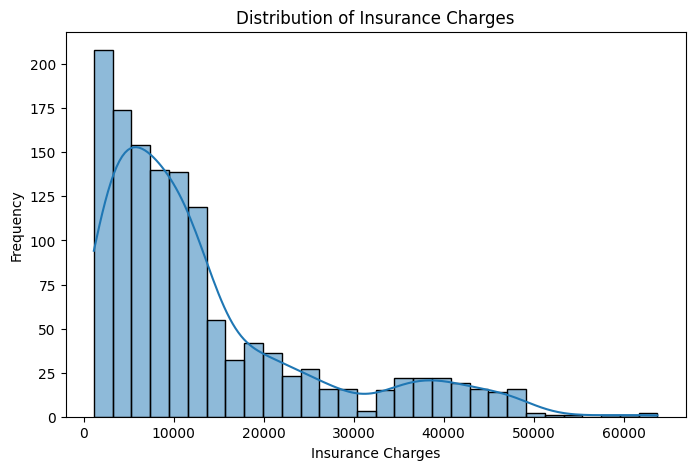

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(
    data=df,
    x='charges',
    bins=30,
    kde=True
)

plt.title('Distribution of Insurance Charges')

plt.xlabel('Insurance Charges')
plt.ylabel('Frequency')

plt.show()

In [17]:
#Understand mean and median
print("mean",df['charges'].mean())
print("median",df['charges'].median())
print("mode",df['charges'].mode()[0])
print("skewness",df['charges'].skew())

mean 13270.422265141257
median 9382.033
mode 1639.5631
skewness 1.5158796580240388


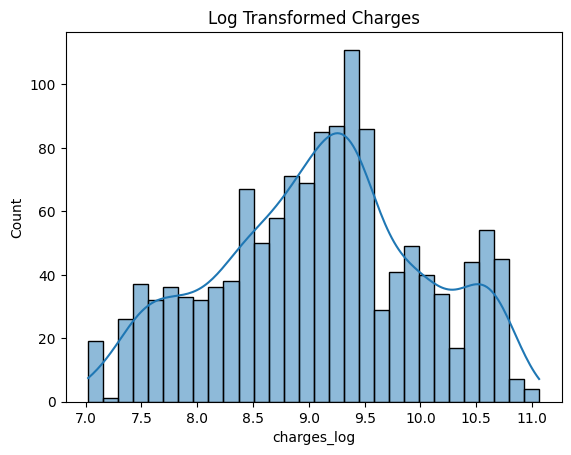

In [19]:
#log transformation import numpy as np

import numpy as np

df['charges_log'] = np.log1p(df['charges'])

sns.histplot(
    data=df,
    x='charges_log',
    bins=30,
    kde=True
)

plt.title('Log Transformed Charges')
plt.show()

In [20]:
#Implement IQR on  Medical Insurance dataset
num_cols = ['age', 'bmi', 'children', 'charges']


for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    print(f"\nColumn: {col}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)

#count the number of outlier
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\n{col}")
    print("Total Outliers:", len(outliers))
    print("Outlier Percentage:",
          round(len(outliers) / len(df) * 100, 2), "%")



Column: age
Q1: 27.0
Q3: 51.0
IQR: 24.0
Lower Bound: -9.0
Upper Bound: 87.0

Column: bmi
Q1: 26.29625
Q3: 34.69375
IQR: 8.3975
Lower Bound: 13.7
Upper Bound: 47.290000000000006

Column: children
Q1: 0.0
Q3: 2.0
IQR: 2.0
Lower Bound: -3.0
Upper Bound: 5.0

Column: charges
Q1: 4740.28715
Q3: 16639.912515
IQR: 11899.625365
Lower Bound: -13109.1508975
Upper Bound: 34489.350562499996

age
Total Outliers: 0
Outlier Percentage: 0.0 %

bmi
Total Outliers: 9
Outlier Percentage: 0.67 %

children
Total Outliers: 0
Outlier Percentage: 0.0 %

charges
Total Outliers: 139
Outlier Percentage: 10.39 %


In [21]:
Q1 = df['bmi'].quantile(0.25)
Q3 = df['bmi'].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

bmi_outliers = df[df['bmi'] > upper_bound]

print(bmi_outliers[['age', 'bmi', 'charges', 'smoker']])

      age    bmi      charges smoker
116    58  49.06  11381.32540     no
286    46  48.07   9432.92530     no
401    47  47.52   8083.91980     no
543    54  47.41  63770.42801    yes
847    23  50.38   2438.05520     no
860    37  47.60  46113.51100    yes
1047   22  52.58  44501.39820    yes
1088   52  47.74   9748.91060     no
1317   18  53.13   1163.46270     no


In [22]:
Q1 = df['charges'].quantile(0.25)
Q3 = df['charges'].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

charges_outliers = df[df['charges'] > upper_bound]

print(
    charges_outliers[
        ['age', 'bmi', 'children', 'smoker', 'region', 'charges']
    ].head(20)
)

     age     bmi  children smoker     region      charges
14    27  42.130         0    yes  southeast  39611.75770
19    30  35.300         0    yes  southwest  36837.46700
23    34  31.920         1    yes  northeast  37701.87680
29    31  36.300         2    yes  southwest  38711.00000
30    22  35.600         0    yes  southwest  35585.57600
34    28  36.400         1    yes  southwest  51194.55914
38    35  36.670         1    yes  northeast  39774.27630
39    60  39.900         0    yes  southwest  48173.36100
49    36  35.200         1    yes  southeast  38709.17600
53    36  34.430         0    yes  southeast  37742.57570
55    58  36.955         2    yes  northwest  47496.49445
82    22  37.620         1    yes  southeast  37165.16380
84    37  34.800         2    yes  southwest  39836.51900
86    57  31.160         0    yes  northwest  43578.93940
94    64  31.300         2    yes  southwest  47291.05500
109   63  35.090         0    yes  southeast  47055.53210
123   44  31.3

In [23]:

# Define charges outliers
charges_outliers = df[df['charges'] > 34489.35]

# Smoking distribution in entire dataset
print("Overall Smoking Distribution:")
print(df['smoker'].value_counts(normalize=True) * 100)

# Smoking distribution among charges outliers
print("\nSmoking Distribution in Charges Outliers:")
print(charges_outliers['smoker'].value_counts(normalize=True) * 100)

# Compare average charges
print("\nAverage Charges by Smoking Status:")
print(df.groupby('smoker')['charges'].mean())

# Compare median charges
print("\nMedian Charges by Smoking Status:")
print(df.groupby('smoker')['charges'].median())


Overall Smoking Distribution:
smoker
no     79.521674
yes    20.478326
Name: proportion, dtype: float64

Smoking Distribution in Charges Outliers:
smoker
yes    97.841727
no      2.158273
Name: proportion, dtype: float64

Average Charges by Smoking Status:
smoker
no      8434.268298
yes    32050.231832
Name: charges, dtype: float64

Median Charges by Smoking Status:
smoker
no      7345.40530
yes    34456.34845
Name: charges, dtype: float64


In [24]:
# Let's calculate the frequency and percentage of each category.
cat_cols = ['sex', 'smoker', 'region']

for col in cat_cols:

    print(f"\nFeature: {col}")

    print("Frequency:")
    print(df[col].value_counts())

    print("\nPercentage:")
    print(df[col].value_counts(normalize=True) * 100)


Feature: sex
Frequency:
sex
male      676
female    662
Name: count, dtype: int64

Percentage:
sex
male      50.523169
female    49.476831
Name: proportion, dtype: float64

Feature: smoker
Frequency:
smoker
no     1064
yes     274
Name: count, dtype: int64

Percentage:
smoker
no     79.521674
yes    20.478326
Name: proportion, dtype: float64

Feature: region
Frequency:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

Percentage:
region
southeast    27.204783
southwest    24.289985
northwest    24.289985
northeast    24.215247
Name: proportion, dtype: float64


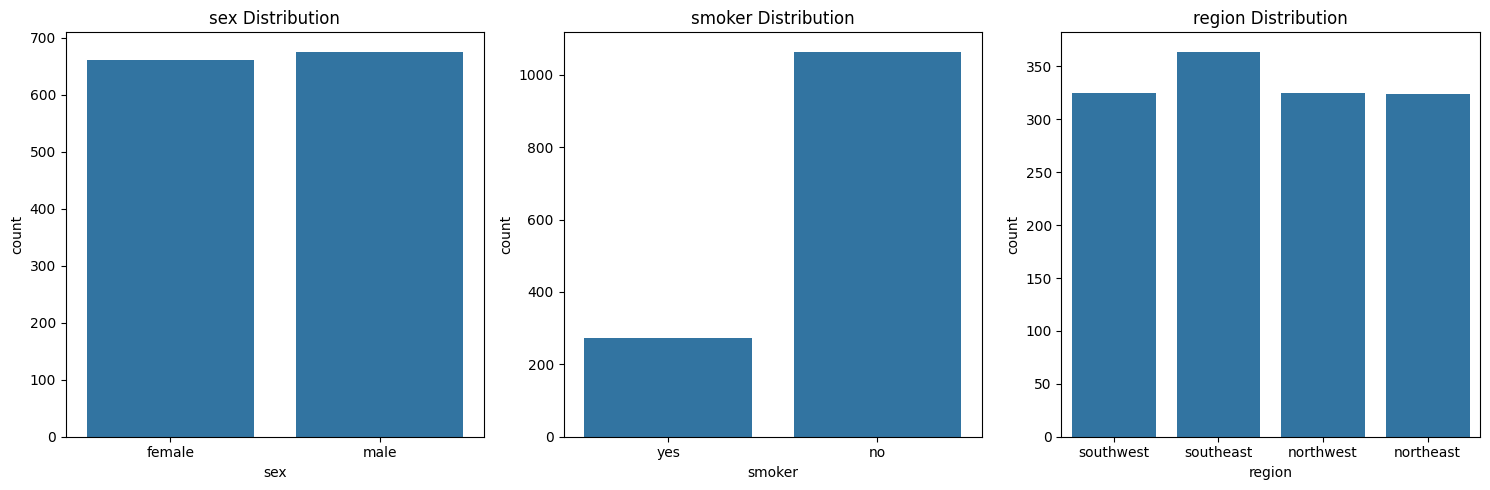

In [25]:
#then visualize
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, cat_cols):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f'{col} Distribution')

plt.tight_layout()
plt.show()

In [26]:
#Feature Relationship Analysis
# Now we need to understand how individual feature related to our target charges
# We will analyze:
# 1. Age vs Charges
# 2. BMI vs Charges
# 3. Children vs Charges
# 4. Sex vs Charges
# 5. Region vs Charges
# 6. Smoker vs Charges

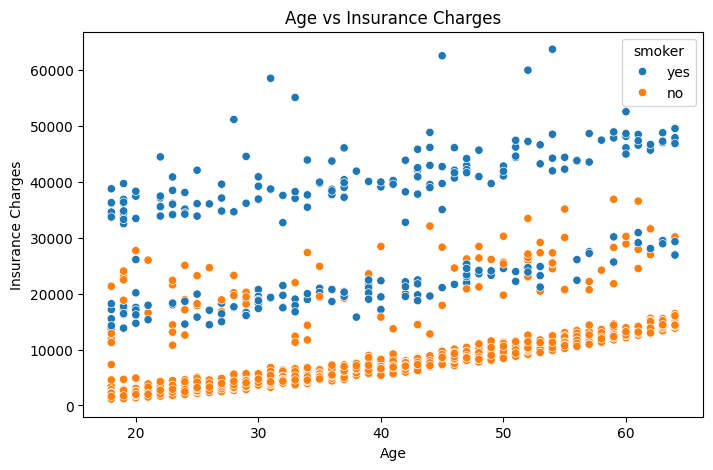

In [33]:
#1 Age vs Charges
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='age',
    y='charges',
    hue='smoker'
)

plt.title('Age vs Insurance Charges')
plt.xlabel('Age')
plt.ylabel('Insurance Charges')

plt.show()

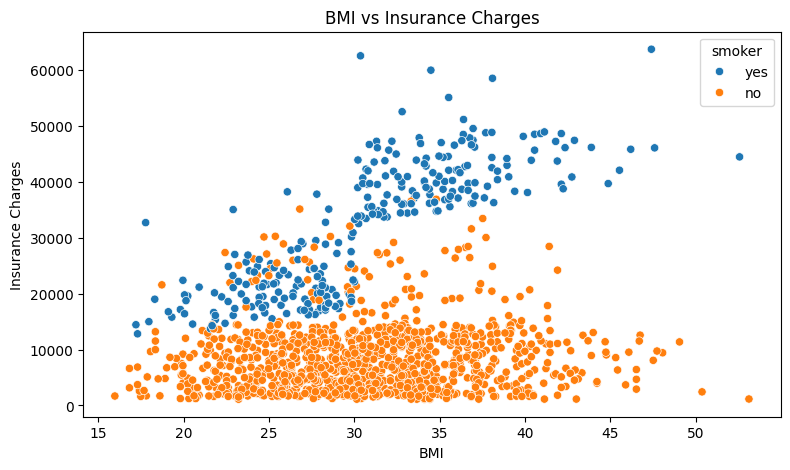

In [34]:
#2. BMI vs Charges
plt.figure(figsize=(9,5))

sns.scatterplot(
    data=df,
    x='bmi',
    y='charges',
    hue='smoker'
)

plt.title('BMI vs Insurance Charges')
plt.xlabel('BMI')
plt.ylabel('Insurance Charges')
plt.show()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          1338 non-null   int64  
 1   sex          1338 non-null   object 
 2   bmi          1338 non-null   float64
 3   children     1338 non-null   int64  
 4   smoker       1338 non-null   object 
 5   region       1338 non-null   object 
 6   charges      1338 non-null   float64
 7   charges_log  1338 non-null   float64
dtypes: float64(3), int64(2), object(3)
memory usage: 83.8+ KB
None


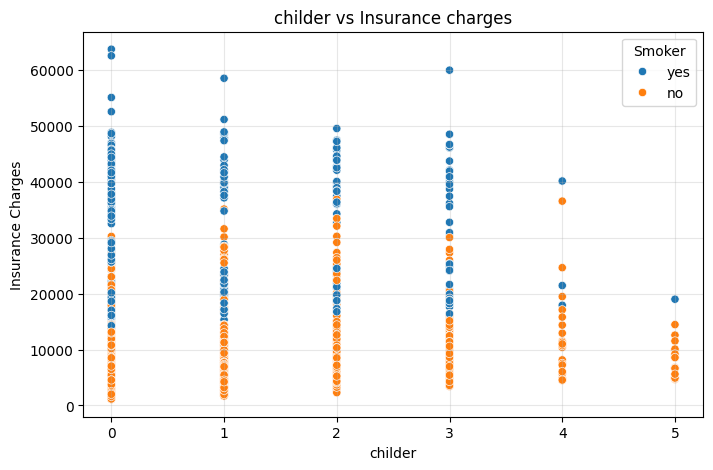

In [38]:
print(df.info())
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x='children',
    y='charges',
    hue='smoker'
)

plt.title('childer vs Insurance charges')
plt.xlabel('childer')
plt.ylabel('Insurance Charges')
plt.legend(title='Smoker')
plt.grid(alpha=0.3)
plt.show()

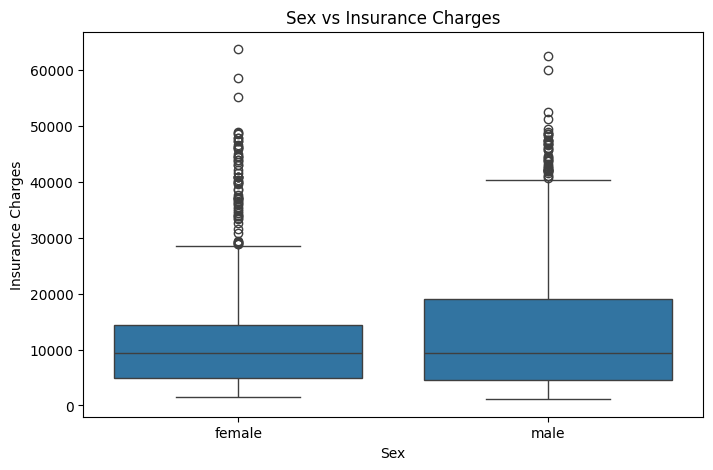

In [39]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='sex',
    y='charges'
)

plt.title('Sex vs Insurance Charges')
plt.xlabel('Sex')
plt.ylabel('Insurance Charges')

plt.show()


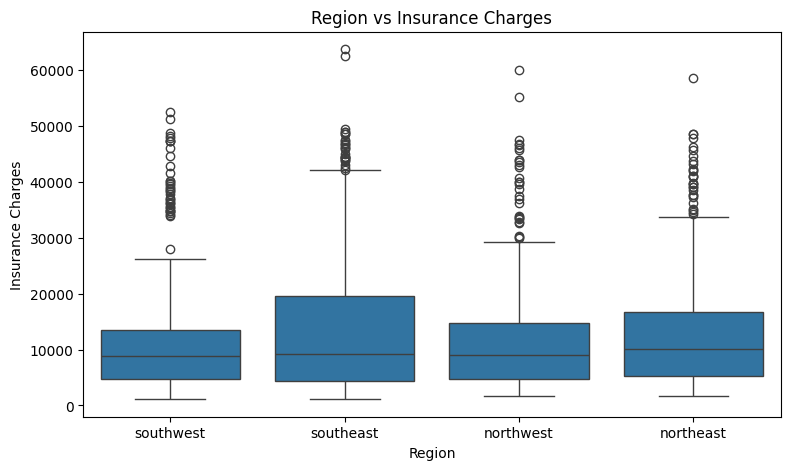

In [40]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='region',
    y='charges'
)

plt.title('Region vs Insurance Charges')
plt.xlabel('Region')
plt.ylabel('Insurance Charges')

plt.show()


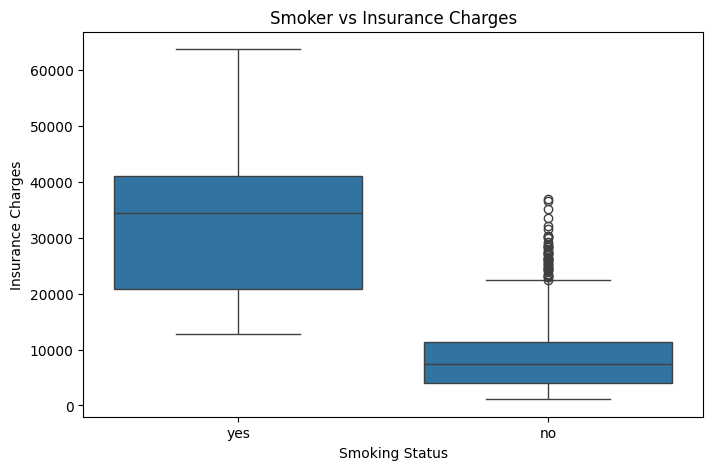

In [41]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='smoker',
    y='charges'
)

plt.title('Smoker vs Insurance Charges')
plt.xlabel('Smoking Status')
plt.ylabel('Insurance Charges')

plt.show()


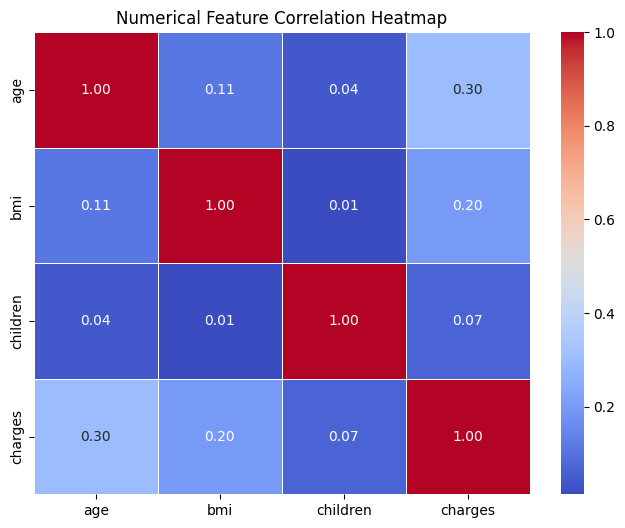

In [42]:

# Select numerical columns
numerical_data = df[
    ['age', 'bmi', 'children', 'charges']
]

# Calculate correlation
correlation = numerical_data.corr()

# Visualize correlation
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Numerical Feature Correlation Heatmap')
plt.show()


In [43]:
print(correlation['charges'].sort_values(ascending=False))

charges     1.000000
age         0.299008
bmi         0.198341
children    0.067998
Name: charges, dtype: float64


In [47]:

# Separate independent and dependent variables

X = df.drop(columns=['charges', 'charges_log'])

y = df['charges']

print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("\nIndependent Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())


X Shape: (1338, 6)
y Shape: (1338,)

Independent Features:
   age     sex     bmi  children smoker     region
0   19  female  27.900         0    yes  southwest
1   18    male  33.770         1     no  southeast
2   28    male  33.000         3     no  southeast
3   33    male  22.705         0     no  northwest
4   32    male  28.880         0     no  northwest

Target Variable:
0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64


In [48]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (1070, 6)
X_test: (268, 6)
y_train: (1070,)
y_test: (268,)


In [49]:

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler
)

# Numerical columns
numerical_cols = ['age', 'bmi', 'children']

# Initialize scalers
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
robust_scaler = RobustScaler()

# Fit and transform training data
standard_data = standard_scaler.fit_transform(
    X_train[numerical_cols]
)

minmax_data = minmax_scaler.fit_transform(
    X_train[numerical_cols]
)

robust_data = robust_scaler.fit_transform(
    X_train[numerical_cols]
)

# Convert to DataFrames
standard_df = pd.DataFrame(
    standard_data,
    columns=numerical_cols
)

minmax_df = pd.DataFrame(
    minmax_data,
    columns=numerical_cols
)

robust_df = pd.DataFrame(
    robust_data,
    columns=numerical_cols
)

print("StandardScaler:")
print(standard_df.describe())

print("\nMinMaxScaler:")
print(minmax_df.describe())

print("\nRobustScaler:")
print(robust_df.describe())


StandardScaler:
                age           bmi      children
count  1.070000e+03  1.070000e+03  1.070000e+03
mean  -1.992176e-16 -4.648410e-17 -2.324205e-17
std    1.000468e+00  1.000468e+00  1.000468e+00
min   -1.518194e+00 -2.417060e+00 -9.111921e-01
25%   -8.784157e-01 -7.210253e-01 -9.111921e-01
50%    1.016470e-02 -5.800739e-02 -8.842793e-02
75%    8.276587e-01  6.515707e-01  7.343363e-01
max    1.751782e+00  3.736342e+00  3.202629e+00

MinMaxScaler:
               age          bmi     children
count  1070.000000  1070.000000  1070.000000
mean      0.464283     0.392801     0.221495
std       0.305956     0.162588     0.243197
min       0.000000     0.000000     0.000000
25%       0.195652     0.275626     0.000000
50%       0.467391     0.383374     0.200000
75%       0.717391     0.498688     0.400000
max       1.000000     1.000000     1.000000

RobustScaler:
               age          bmi     children
count  1070.000000  1070.000000  1070.000000
mean     -0.005958     0.04

In [51]:
numerical_cols = ['age', 'bmi', 'children']

categorical_cols = ['sex', 'smoker', 'region']

In [52]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    drop='first',
    handle_unknown='ignore'
)

# Combine both transformers
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

print(preprocessor)


ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['age', 'bmi', 'children']),
                                ('cat',
                                 OneHotEncoder(drop='first',
                                               handle_unknown='ignore'),
                                 ['sex', 'smoker', 'region'])])


In [53]:

# Fit on training data and transform
X_train_transformed = preprocessor.fit_transform(X_train)

# Transform test data
X_test_transformed = preprocessor.transform(X_test)

print("Training Shape:", X_train_transformed.shape)
print("Testing Shape:", X_test_transformed.shape)


Training Shape: (1070, 8)
Testing Shape: (268, 8)


In [54]:

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Convert to DataFrame
X_train_transformed_df = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_train.index
)

print(X_train_transformed_df.head())


      num__age  num__bmi  num__children  cat__sex_male  cat__smoker_yes  \
560   0.472227 -1.756525       0.734336            0.0              0.0   
1285  0.543313 -1.033082      -0.911192            0.0              0.0   
1142  0.898745 -0.943687      -0.911192            0.0              0.0   
969  -0.025379  0.622393       3.202629            0.0              0.0   
486   1.040918 -1.504893       1.557100            0.0              0.0   

      cat__region_northwest  cat__region_southeast  cat__region_southwest  
560                     1.0                    0.0                    0.0  
1285                    0.0                    0.0                    0.0  
1142                    0.0                    1.0                    0.0  
969                     0.0                    1.0                    0.0  
486                     1.0                    0.0                    0.0  


In [55]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Create pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [56]:

import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict on testing data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results
print("Model Evaluation Results")

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


Model Evaluation Results
MAE: 4181.194473753649
MSE: 33596915.85136146
RMSE: 5796.2846592762735
R2 Score: 0.7835929767120723


In [57]:

import pandas as pd

# Create new customer data
new_customer = pd.DataFrame({
    'age': [30],
    'bmi': [25.5],
    'children': [1],
    'sex': ['male'],
    'smoker': ['no'],
    'region': ['southeast']
})

# Predict insurance cost
predicted_cost = model.predict(new_customer)

print("Predicted Medical Insurance Cost:",
      predicted_cost[0])


Predicted Medical Insurance Cost: 4122.734994621635
